<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Sesiones/Sesion10_Score_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



Repaso de estadistica


El valor esperado (expected value o esperanza matemática) es el promedio de los valores que puede tomar una variable aleatoria, ponderados por sus probabilidades.

\begin{equation}
\mathbb  E[X] = \sum_{x} x P(X=x)
\end{equation}

en forma integral, viene dada por:

\begin{equation}
\mathbb E[X]
=
\int_{-\infty}^{\infty}x\,p(x)\,dx.
\end{equation}


Supongamos que tenemos el lanzamiento de un dado, cada unas de las caras tiene una probablidad de 1/6, de ser lanzado, luego:

\begin{equation}
\mathbb  E[X] = \sum_{x} x P(X=x) = (1+2+3+4+5+6)\frac{1}{6}=3.5
\end{equation}

Lanzamiento de una moneda:

S = {HH, TH, HT, TT}

Número de caras obtenidas en el lazamiento de una moneda, ¿como se computa?

\begin{equation}
\mathbb  E[X] = \sum_{x} x P(X=x) = 2(1/4)+1(1/4)+1(1/4)+0(1/4)=1
\end{equation}

En promedio obtenemso, una cara por cada experimento.

Tarea: Generar una distribucion empirica del lanzamiento de monedas y comprobar que el valor esperado es 1.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import multivariate_normal
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff


# Probabilidades y campos score






In [ ]:
# @title Densidades, curvas de nivel y muestras { display-mode: "form" }

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import multivariate_normal

# Distribuciones
p_data = multivariate_normal(mean=[3, 3], cov=np.eye(2))
p_modelo = multivariate_normal(mean=[-3, -3], cov=np.eye(2))

# Malla para las densidades
limites = [-7, 7]
x1 = np.linspace(*limites, 180)
x2 = np.linspace(*limites, 180)
X1, X2 = np.meshgrid(x1, x2)
posiciones = np.stack([X1, X2], axis=-1)

Z_data = p_data.pdf(posiciones)
Z_modelo = p_modelo.pdf(posiciones)

# Muestras reproducibles
rng = np.random.default_rng(42)
n = 500

muestra_data = p_data.rvs(size=n, random_state=rng)
muestra_modelo = p_modelo.rvs(size=n, random_state=rng)

distribuciones = [
    (Z_data, muestra_data, "#2563eb", "Datos"),
    (Z_modelo, muestra_modelo, "#e66101", "Modelo")
]

# Dos paneles lado a lado
fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "surface"}, {"type": "xy"}]],
    subplot_titles=[
        "Densidades teóricas",
        "Curvas de nivel y muestras aleatorias"
    ],
    horizontal_spacing=0.10
)

for Z, muestra, color, nombre in distribuciones:
    # Izquierda: superficie 3D
    Z_visible = np.where(Z > Z.max() * 0.002, Z, np.nan)

    fig.add_trace(
        go.Surface(
            x=X1,
            y=X2,
            z=Z_visible,
            colorscale=[[0, color], [1, color]],
            showscale=False,
            showlegend=False,
            name=nombre,
            legendgroup=nombre
        ),
        row=1, col=1
    )

    # Derecha: curvas de nivel
    fig.add_trace(
        go.Contour(
            x=x1,
            y=x2,
            z=Z,
            autocontour=False,
            contours=dict(
                start=0.02,
                end=0.14,
                size=0.02,
                coloring="lines"
            ),
            colorscale=[[0, color], [1, color]],
            line=dict(width=2),
            showscale=False,
            showlegend=False,
            legendgroup=nombre,
            hoverinfo="skip"
        ),
        row=1, col=2
    )

# Añadir los puntos sobre las curvas de nivel
for Z, muestra, color, nombre in distribuciones:
    fig.add_trace(
        go.Scatter(
            x=muestra[:, 0],
            y=muestra[:, 1],
            mode="markers",
            marker=dict(
                color=color,
                size=4,
                opacity=0.40
            ),
            name=nombre,
            legendgroup=nombre,
            hovertemplate=(
                "x₁ = %{x:.2f}<br>"
                "x₂ = %{y:.2f}<extra>%{fullData.name}</extra>"
            )
        ),
        row=1, col=2
    )

# Ejes del panel 2D
fig.update_xaxes(
    title_text="x₁",
    range=limites,
    constrain="domain",
    row=1, col=2
)

fig.update_yaxes(
    title_text="x₂",
    range=limites,
    scaleanchor="x",
    scaleratio=1,
    constrain="domain",
    row=1, col=2
)

fig.update_layout(
    template="plotly_white",
    width=1100,
    height=550,
    scene=dict(
        xaxis=dict(title="x₁", range=limites),
        yaxis=dict(title="x₂", range=limites),
        zaxis=dict(title="Densidad", range=[0, 0.17]),
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.7)
    ),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.08
    ),
    margin=dict(l=30, r=30, t=65, b=60)
)

fig.show()

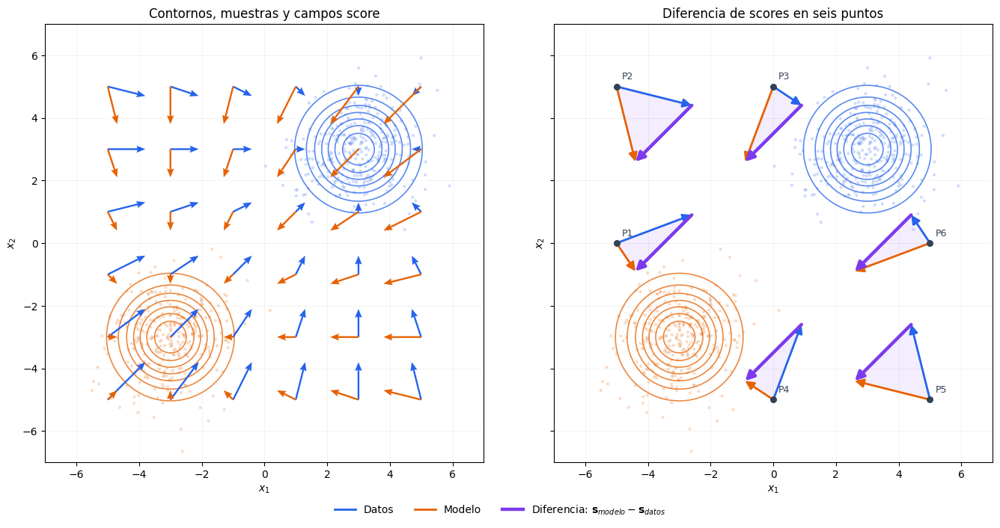

In [ ]:
# @title Distribuciones, campos score y diferencia { display-mode: "form" }

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

AZUL = "#2563eb"
NARANJA = "#e66101"
MORADO = "#7c3aed"

mu_data = np.array([3.0, 3.0])
mu_modelo = np.array([-3.0, -3.0])

# Densidades gaussianas con covarianza identidad
x = np.linspace(-7, 7, 200)
X, Y = np.meshgrid(x, x)

def densidad(mu):
    return np.exp(
        -0.5 * ((X - mu[0])**2 + (Y - mu[1])**2)
    ) / (2 * np.pi)

# Muestras reproducibles
rng = np.random.default_rng(42)
muestra_data = rng.normal(size=(300, 2)) + mu_data
muestra_modelo = rng.normal(size=(300, 2)) + mu_modelo

fig, axes = plt.subplots(
    1, 2, figsize=(14, 7),
    sharex=True, sharey=True
)

# Contornos y muestras en ambos paneles
for ax in axes:
    for mu, muestra, color in [
        (mu_data, muestra_data, AZUL),
        (mu_modelo, muestra_modelo, NARANJA)
    ]:
        ax.scatter(
            muestra[:, 0], muestra[:, 1],
            s=9, color=color, alpha=0.22,
            edgecolors="none", zorder=1
        )

        ax.contour(
            X, Y, densidad(mu),
            levels=np.arange(0.02, 0.15, 0.02),
            colors=color, linewidths=1.2,
            alpha=0.75, zorder=2
        )

    ax.set(
        xlim=(-7, 7), ylim=(-7, 7),
        xlabel=r"$x_1$", ylabel=r"$x_2$"
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)

# ---------------------------------------------------
# IZQUIERDA: ambos campos sobre una malla común
# ---------------------------------------------------
eje = np.linspace(-5, 5, 6)
Q1, Q2 = np.meshgrid(eje, eje)

escala_campo = 0.15

for mu, color in [(mu_data, AZUL), (mu_modelo, NARANJA)]:
    axes[0].quiver(
        Q1, Q2,
        escala_campo * (mu[0] - Q1),
        escala_campo * (mu[1] - Q2),
        angles="xy",
        scale_units="xy",
        scale=1,
        pivot="tail",
        color=color,
        width=0.004,
        headwidth=4,
        headlength=5,
        zorder=3
    )

axes[0].set_title("Contornos, muestras y campos score")

# ---------------------------------------------------
# DERECHA: triángulos en seis puntos representativos
# ---------------------------------------------------
puntos = np.array([
    [-5.0,  0.0],
    [-5.0,  5.0],
    [ 0.0,  5.0],
    [ 0.0, -5.0],
    [ 5.0, -5.0],
    [ 5.0,  0.0]
])

# Los tres vectores de cada triángulo usan la misma escala
escala_triangulo = 0.30

def flecha(ax, inicio, fin, color, grosor=2.0):
    ax.annotate(
        "",
        xy=fin,
        xytext=inicio,
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            lw=grosor,
            mutation_scale=17,
            shrinkA=0,
            shrinkB=0
        ),
        zorder=6
    )

for i, punto in enumerate(puntos, start=1):
    # Ambos scores se evalúan en el mismo punto
    score_data = mu_data - punto
    score_modelo = mu_modelo - punto

    punta_data = punto + escala_triangulo * score_data
    punta_modelo = punto + escala_triangulo * score_modelo

    # Sombreado tenue para destacar cada triángulo
    triangulo = np.array([punto, punta_data, punta_modelo])

    axes[1].fill(
        triangulo[:, 0],
        triangulo[:, 1],
        color=MORADO,
        alpha=0.09,
        zorder=3
    )

    # Los dos scores parten del punto de evaluación
    flecha(axes[1], punto, punta_data, AZUL)
    flecha(axes[1], punto, punta_modelo, NARANJA)

    # Diferencia: desde la punta azul hasta la naranja
    flecha(
        axes[1], punta_data, punta_modelo,
        MORADO, grosor=3.2
    )

    axes[1].scatter(
        punto[0], punto[1],
        s=30, color="#334155", zorder=7
    )

    axes[1].annotate(
        f"P{i}",
        xy=punto,
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9,
        color="#334155",
        zorder=8
    )

axes[1].set_title("Diferencia de scores en seis puntos")

# Leyenda común
leyenda = [
    Line2D(
        [0], [0], color=AZUL, lw=2,
        label="Datos"
    ),
    Line2D(
        [0], [0], color=NARANJA, lw=2,
        label="Modelo"
    ),
    Line2D(
        [0], [0], color=MORADO, lw=3.2,
        label=r"Diferencia: $\mathbf{s}_{modelo}-\mathbf{s}_{datos}$"
    )
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.02)
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

In [ ]:
# @title Probabilidades y campos score { display-mode: "form" }

# Malla para las densidades
x = np.linspace(-7, 7, 150)
X1, X2 = np.meshgrid(x, x)

# Malla para los campos vectoriales
eje = np.linspace(-6, 6, 13)
Q1, Q2 = np.meshgrid(eje, eje)

azul = "#2563eb"
naranja = "#e66101"
morado = "#7c3aed"

mu_data = np.array([3.0, 3.0])
mu_inicial = np.array([-3.0, -3.0])


def densidad(mu):
    return np.exp(
        -0.5 * ((X1 - mu[0])**2 + (X2 - mu[1])**2)
    ) / (2 * np.pi)


def contorno(mu, color):
    return go.Contour(
        x=x, y=x, z=densidad(mu),
        autocontour=False,
        contours=dict(
            start=0.02, end=0.14, size=0.02,
            coloring="lines"
        ),
        colorscale=[[0, color], [1, color]],
        line=dict(width=1.5),
        opacity=0.65,
        showscale=False,
        showlegend=False,
        hoverinfo="skip"
    )


def campo(U, V, color, nombre):
    # Un campo nulo se representa con una traza vacía.
    if np.allclose(U, 0) and np.allclose(V, 0):
        return go.Scatter(
            x=[], y=[], mode="lines",
            line=dict(color=color, width=1.4),
            name=nombre, hoverinfo="skip"
        )

    traza = ff.create_quiver(
        Q1.ravel(), Q2.ravel(),
        U.ravel(), V.ravel(),
        scale=0.08,
        arrow_scale=0.25,
        line=dict(color=color, width=1.4)
    ).data[0]

    traza.update(name=nombre, hoverinfo="skip")
    return traza


def trazas_modelo(alpha):
    mu = (1 - alpha) * mu_inicial + alpha * mu_data

    score1 = mu[0] - Q1
    score2 = mu[1] - Q2

    diferencia1 = score1 - (mu_data[0] - Q1)
    diferencia2 = score2 - (mu_data[1] - Q2)

    return [
        contorno(mu, naranja),

        campo(
            score1, score2,
            naranja, "Score del modelo"
        ),

        go.Scatter(
            x=[mu[0]], y=[mu[1]],
            mode="markers",
            marker=dict(
                color=naranja, size=12,
                symbol="circle-open", line=dict(width=2)
            ),
            showlegend=False,
            hoverinfo="skip"
        ),

        campo(
            diferencia1, diferencia2,
            morado, "Diferencia de scores"
        )
    ]


fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "Probabilidades y scores",
        "Diferencia: score del modelo − score de los datos"
    ),
    horizontal_spacing=0.10
)

# Trazas fijas de los datos: índices 0, 1 y 2
fig.add_trace(contorno(mu_data, azul), row=1, col=1)

fig.add_trace(
    campo(
        mu_data[0] - Q1,
        mu_data[1] - Q2,
        azul, "Score de los datos"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=[mu_data[0]], y=[mu_data[1]],
        mode="markers",
        marker=dict(color=azul, size=10, symbol="x"),
        showlegend=False,
        hoverinfo="skip"
    ),
    row=1, col=1
)

# Trazas variables: índices 3, 4, 5 y 6
iniciales = trazas_modelo(0)

for traza in iniciales[:3]:
    fig.add_trace(traza, row=1, col=1)

fig.add_trace(iniciales[3], row=1, col=2)

# Estados del deslizador
alphas = np.linspace(0, 1, 10)

fig.frames = [
    go.Frame(
        name=str(i),
        data=trazas_modelo(alpha),
        traces=[3, 4, 5, 6]
    )
    for i, alpha in enumerate(alphas)
]

pasos = [
    dict(
        method="animate",
        label=f"{alpha:.2f}",
        args=[
            [str(i)],
            dict(
                mode="immediate",
                frame=dict(duration=0, redraw=True),
                transition=dict(duration=0)
            )
        ]
    )
    for i, alpha in enumerate(alphas)
]

# Escalas fijas: permiten comparar longitudes de las flechas
for columna in (1, 2):
    fig.update_xaxes(
        title_text="x₁",
        range=[-7, 7],
        constrain="domain",
        row=1, col=columna
    )

    fig.update_yaxes(
        title_text="x₂",
        range=[-7, 7],
        scaleanchor="x" if columna == 1 else "x2",
        scaleratio=1,
        row=1, col=columna
    )

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=700,
    margin=dict(l=55, r=30, t=65, b=170),
    legend=dict(
        orientation="h",
        x=0.5, xanchor="center",
        y=-0.12
    ),
    sliders=[dict(
        active=0,
        currentvalue=dict(prefix="Acercamiento α = "),
        steps=pasos,
        x=0.08,
        len=0.88,
        y=-0.25,
        pad=dict(t=15)
    )]
)

fig.show()

# Construccion basada en

https://arxiv.org/pdf/2101.03288


\begin{equation}
p_\theta(\mathbf x)
=
\frac{1}{Z_\theta}e^{-\beta E_\theta(\mathbf x)}.
\end{equation}

Tomando el logaritmo,
\begin{equation}
\log p_\theta(\mathbf x)
=
-\beta E_\theta(\mathbf x)-\log Z_\theta.
\end{equation}

Como $Z_\theta$ es independiente de $\mathbf x$, definimos


\begin{equation}
\mathbf s_\theta(\mathbf x)
\equiv
\nabla_{\mathbf x}\log p_\theta(\mathbf x)
=
-\beta\nabla_{\mathbf x}E_\theta(\mathbf x).
\end{equation}

Para la distribución de los datos, conservamos directamente

\begin{equation}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x).
\end{equation}
Entonces, la diferencia entre ambos campos es precisamente
\begin{equation}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x).
\end{equation}


\begin{equation}
J(\theta)
=
\frac12
\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\left\|
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x)
\right\|^2
\right].
\end{equation}


\begin{equation}
J(\theta)
=
\frac12
\int
p_{\mathrm{data}}(\mathbf x)
\left\|
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x)
\right\|^2
\,d\mathbf x.
\end{equation}

La anterior ecuación se puede transformar en:


Partimos de
\begin{equation}
J(\theta)
=
\frac12
\int
p_{\mathrm{data}}(\mathbf x)
\left\|
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x)
\right\|^2
\,d\mathbf x.
\end{equation}


Utilizando la identidad
\begin{equation}
\|\mathbf a-\mathbf b\|^2
=
\|\mathbf a\|^2-2\mathbf a\cdot\mathbf b+\|\mathbf b\|^2,
\end{equation}

obtenemos


\begin{equation}
\begin{aligned}
J(\theta)
={}&
\frac12\int
p_{\mathrm{data}}(\mathbf x)
\left\|\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)\right\|^2
\,d\mathbf x
\\
&-
\int
p_{\mathrm{data}}(\mathbf x)\,
\mathbf s_\theta(\mathbf x)\cdot
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
\,d\mathbf x
\\
&+
\frac12\int
p_{\mathrm{data}}(\mathbf x)
\|\mathbf s_\theta(\mathbf x)\|^2
\,d\mathbf x.
\end{aligned}
\end{equation}

El primer término depende únicamente de la distribución de los datos, así que lo llamamos


\begin{equation}
C=
\frac12\int
p_{\mathrm{data}}(\mathbf x)
\left\|\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)\right\|^2
\,d\mathbf x.
\end{equation}





- Transformemos el término cruzado, que contiene el score desconocido. Como


\begin{equation}
p_{\mathrm{data}}(\mathbf x)
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
=
\nabla_{\mathbf x}p_{\mathrm{data}}(\mathbf x),
\end{equation}


tenemos
\begin{equation}
\int
p_{\mathrm{data}}(\mathbf x)\,
\mathbf s_\theta(\mathbf x)\cdot
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
\,d\mathbf x
=\sum_{i=1}^{d}
\int
s_{\theta,i}(\mathbf x)
\frac{\partial p_{\mathrm{data}}(\mathbf x)}{\partial x_i}
\,d\mathbf x.
\end{equation}



\begin{equation}
J(\theta)
=
C
-
\int
\mathbf s_\theta\cdot\nabla_{\mathbf x}p_{\mathrm{data}}
\,d\mathbf x
+
\frac12\int
p_{\mathrm{data}}\|\mathbf s_\theta\|^2
\,d\mathbf x.
\end{equation}

El producto $p_{\mathrm{data}}\mathbf s_\theta$ es un campo vectorial con componentes

\begin{equation}
p_{\mathrm{data}}\mathbf s_\theta
=
\left(
p_{\mathrm{data}}s_{\theta,1},
\ldots,
p_{\mathrm{data}}s_{\theta,d}
\right).
\end{equation}

Su divergencia se define como

\begin{equation}
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
=
\sum_{i=1}^{d}
\frac{\partial}{\partial x_i}
\left(p_{\mathrm{data}}s_{\theta,i}\right).
\end{equation}

Para cada componente aplicamos la regla del producto:

\begin{equation}
\frac{\partial}{\partial x_i}
\left(p_{\mathrm{data}}s_{\theta,i}\right)
=
s_{\theta,i}
\frac{\partial p_{\mathrm{data}}}{\partial x_i}
+
p_{\mathrm{data}}
\frac{\partial s_{\theta,i}}{\partial x_i}.
\end{equation}

Sumamos y separamos los términos:

\begin{equation}
\begin{aligned}
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
&=
\sum_{i=1}^{d}
s_{\theta,i}
\frac{\partial p_{\mathrm{data}}}{\partial x_i}
+
p_{\mathrm{data}}
\sum_{i=1}^{d}
\frac{\partial s_{\theta,i}}{\partial x_i}
\\
&=
\mathbf s_\theta\cdot\nabla_{\mathbf x}p_{\mathrm{data}}
+
p_{\mathrm{data}}\,
\nabla_{\mathbf x}\cdot\mathbf s_\theta.
\end{aligned}
\end{equation}

Despejamos el término que aparece en nuestra función objetivo:

\begin{equation}
\mathbf s_\theta\cdot\nabla_{\mathbf x}p_{\mathrm{data}}
=
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
-
p_{\mathrm{data}}\,
\nabla_{\mathbf x}\cdot\mathbf s_\theta.
\end{equation}

Sustituimos esta identidad en la integral.

\begin{equation}
\begin{aligned}
J(\theta)
={}&
C
-
\int
\left[
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
-
p_{\mathrm{data}}\,
\nabla_{\mathbf x}\cdot\mathbf s_\theta
\right]
\,d\mathbf x
\\
&+
\frac12\int
p_{\mathrm{data}}\|\mathbf s_\theta\|^2
\,d\mathbf x.
\end{aligned}
\end{equation}

Distribuyendo el signo negativo,
\begin{equation}
\begin{aligned}
J(\theta)
={}&
C
-
\int
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
\,d\mathbf x
\\
&+
\int
p_{\mathrm{data}}\,
\nabla_{\mathbf x}\cdot\mathbf s_\theta
\,d\mathbf x
\\
&+
\frac12\int
p_{\mathrm{data}}\|\mathbf s_\theta\|^2
\,d\mathbf x.
\end{aligned}
\end{equation}
La integral de la divergencia es un término de frontera. En un dominio $\Omega$, el teorema de la divergencia establece
\begin{equation}
\int_\Omega
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
\,d\mathbf x
=
\int_{\partial\Omega}
p_{\mathrm{data}}\mathbf s_\theta\cdot\mathbf n\,dS,
\end{equation}
donde $\mathbf n$ es la normal exterior.

Suponemos que este flujo de frontera es cero. En $\mathbb R^d$, requerimos que el flujo a través de superficies que se alejan al infinito tienda a cero. También suponemos suficiente regularidad e integrabilidad para las operaciones anteriores.

\begin{equation}
\int
\nabla_{\mathbf x}\cdot
\left(p_{\mathrm{data}}\mathbf s_\theta\right)
\,d\mathbf x
=
0.
\end{equation}

Queda entonces
\begin{equation}
J(\theta)
=
C+
\int
p_{\mathrm{data}}(\mathbf x)
\left[
\frac12\|\mathbf s_\theta(\mathbf x)\|^2
+
\nabla_{\mathbf x}\cdot\mathbf s_\theta(\mathbf x)
\right]
\,d\mathbf x.
\end{equation}



Como \(C\) es independiente de \(\theta\), podemos minimizar el objetivo equivalente
\begin{equation}
 L_{\mathrm{SM}}(\theta)
=
\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\frac12\|\mathbf s_\theta(\mathbf x)\|^2
+
\nabla_{\mathbf x}\cdot\mathbf s_\theta(\mathbf x)
\right].
\end{equation}
Escrito completamente por componentes,
\begin{equation}
 L_{\mathrm{SM}}(\theta)
=
\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\sum_{i=1}^{d}
\left(
\frac12 s_{\theta,i}(\mathbf x)^2
+
\frac{\partial s_{\theta,i}(\mathbf x)}{\partial x_i}
\right)
\right].
\end{equation}
Con \(N\) muestras de los datos, lo estimamos mediante
\begin{equation}
\widehat{ L}_{\mathrm{SM}}(\theta)
=
\frac1N
\sum_{n=1}^{N}
\sum_{i=1}^{d}
\left[
\frac12s_{\theta,i}(\mathbf x_n)^2
+
\frac{\partial s_{\theta,i}}{\partial x_i}(\mathbf x_n)
\right].
\end{equation}

El costo computacional depende de la complejidad de la red neuronal utilizada para representar el score y del cálculo de su divergencia, que corresponde a la traza de su matriz jacobiana. En espacios de alta dimensión, como los de imágenes con muchos píxeles, calcular esta traza de forma exacta puede resultar costoso y limitar la escalabilidad del método.

In [ ]:
# @title Distribuciones y proyecciones aleatorias en todo el campo { display-mode: "form" }

import numpy as np
import plotly.graph_objects as go
import plotly.figure_factory as ff
from plotly.subplots import make_subplots

AZUL = "#2563eb"
NARANJA = "#e66101"
MORADO = "#7c3aed"
VERDE = "#059669"
GRIS = "#64748b"

mu_data = np.array([3.0, 3.0])
mu_inicial = np.array([-3.0, -3.0])

semilla = 42
rng = np.random.default_rng(semilla)

# Dirección fija del segundo panel.
v = rng.normal(size=2)
v /= np.linalg.norm(v)

# Malla de densidades.
x = np.linspace(-8, 8, 160)
X1, X2 = np.meshgrid(x, x)

# Malla de scores del primer panel.
eje = np.linspace(-6, 6, 9)
Q1, Q2 = np.meshgrid(eje, eje)

# Puntos del tercer panel: malla para visualizar todo el campo.
# En entrenamiento se utilizan muestras de p_data.
eje_local = np.linspace(-5, 5, 5)
P1, P2 = np.meshgrid(eje_local, eje_local)
puntos = np.column_stack([P1.ravel(), P2.ravel()])

# Una dirección aleatoria UNITARIA por punto.
direcciones = rng.normal(size=puntos.shape)
direcciones /= np.linalg.norm(direcciones, axis=1, keepdims=True)

# Factor común para las flechas del tercer panel.
# Reducimos su tamaño para que no se superpongan.
ESCALA_LOCAL = 0.20


def densidad(mu):
    return np.exp(
        -0.5 * ((X1 - mu[0])**2 + (X2 - mu[1])**2)
    ) / (2 * np.pi)


def contorno(mu, color, nombre, ancho=2):
    return go.Contour(
        x=x, y=x, z=densidad(mu),
        autocontour=False,
        contours=dict(
            start=0.02,
            end=0.14,
            size=0.02,
            coloring="lines"
        ),
        colorscale=[[0, color], [1, color]],
        line=dict(width=ancho),
        opacity=0.85,
        showscale=False,
        showlegend=True,
        name=nombre,
        hoverinfo="skip"
    )


def flechas(origenes, vectores, color, nombre,
            escala=1.0, ancho=2, leyenda=True):
    """Dibuja uno o varios vectores con el mismo factor de escala."""
    origenes = np.asarray(origenes).reshape(-1, 2)
    vectores = np.asarray(vectores).reshape(-1, 2)

    # Evita problemas con quiver cuando todas las flechas son nulas.
    if np.allclose(vectores, 0):
        return go.Scatter(
            x=origenes[:, 0],
            y=origenes[:, 1],
            mode="markers",
            marker=dict(size=4, color=color),
            name=nombre,
            showlegend=leyenda,
            hoverinfo="skip"
        )

    traza = ff.create_quiver(
        origenes[:, 0], origenes[:, 1],
        vectores[:, 0], vectores[:, 1],
        scale=escala,
        arrow_scale=0.20,
        line=dict(color=color, width=ancho)
    ).data[0]

    traza.update(
        name=nombre,
        showlegend=leyenda,
        hoverinfo="skip"
    )
    return traza


def segmentos(inicios, finales, color, nombre,
              dash="dot", leyenda=False):
    xx, yy = [], []

    for a, b in zip(inicios, finales):
        xx.extend([a[0], b[0], None])
        yy.extend([a[1], b[1], None])

    return go.Scatter(
        x=xx, y=yy,
        mode="lines",
        line=dict(color=color, width=1.2, dash=dash),
        name=nombre,
        showlegend=leyenda,
        hoverinfo="skip"
    )


def campo_score(mu, color):
    origenes = np.column_stack([Q1.ravel(), Q2.ravel()])
    scores = mu - origenes

    traza = flechas(
        origenes, scores, color, "Score",
        escala=0.07, ancho=1, leyenda=False
    )
    traza.opacity = 0.4
    return traza


def centro(mu, color, simbolo):
    return go.Scatter(
        x=[mu[0]], y=[mu[1]],
        mode="markers",
        marker=dict(
            size=11,
            color=color,
            symbol=simbolo,
            line=dict(width=2)
        ),
        showlegend=False,
        hoverinfo="skip"
    )


def trazas_variables(alpha):
    mu = (1 - alpha) * mu_inicial + alpha * mu_data

    # Diferencia constante en este ejemplo de gaussianas:
    # s_modelo(x) - s_data(x) = mu_modelo - mu_data.
    delta = mu - mu_data

    # Panel 2: una dirección fija.
    z = float(v @ delta)
    proyeccion = z * v

    # Panel 3: una dirección por punto.
    diferencias = np.broadcast_to(delta, puntos.shape)
    z_local = np.sum(direcciones * diferencias, axis=1)
    proy_local = z_local[:, None] * direcciones

    extremos_delta = puntos + ESCALA_LOCAL * diferencias
    extremos_proy = puntos + ESCALA_LOCAL * proy_local

    return [
        # Panel 1.
        contorno(mu, NARANJA, "Distribución del modelo"),
        campo_score(mu, NARANJA),
        centro(mu, NARANJA, "circle-open"),

        # Panel 2.
        flechas(
            [[0, 0]], [delta], MORADO,
            "Diferencia Δs", ancho=4
        ),
        flechas(
            [[0, 0]], [proyeccion], VERDE,
            "Proyección de Δs", ancho=3
        ),
        segmentos(
            [delta], [proyeccion], GRIS, "Perpendicular"
        ),
        go.Scatter(
            x=[0], y=[7.4],
            mode="text",
            text=[
                f"Δs = ({delta[0]:.2f}, {delta[1]:.2f})"
                f"<br>vᵀΔs = {z:.2f}"
            ],
            textposition="bottom center",
            textfont=dict(size=12),
            showlegend=False,
            hoverinfo="skip"
        ),

        # Panel 3.
        flechas(
            puntos, diferencias, MORADO,
            "Diferencias locales",
            escala=ESCALA_LOCAL, ancho=2, leyenda=False
        ),
        flechas(
            puntos, proy_local, VERDE,
            "Proyecciones locales",
            escala=ESCALA_LOCAL, ancho=3, leyenda=False
        ),
        segmentos(
            extremos_delta, extremos_proy,
            GRIS, "Perpendiculares locales"
        )
    ]


fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=(
        "Distribuciones y scores",
        "Una dirección fija",
        "Una dirección aleatoria por punto"
    ),
    horizontal_spacing=0.055
)

# Panel 1: distribución fija de los datos.
fig.add_trace(
    contorno(mu_data, AZUL, "Distribución de los datos", ancho=4),
    row=1, col=1
)
fig.add_trace(campo_score(mu_data, AZUL), row=1, col=1)
fig.add_trace(centro(mu_data, AZUL, "x"), row=1, col=1)

# Panel 2: eje y vector unitario.
fig.add_trace(
    segmentos(
        [-20 * v], [20 * v],
        GRIS, "Ejes de proyección",
        dash="dash", leyenda=True
    ),
    row=1, col=2
)
fig.add_trace(
    flechas(
        [[0, 0]], [v], GRIS, "v",
        ancho=2, leyenda=False
    ),
    row=1, col=2
)
fig.add_trace(
    centro(np.zeros(2), "#0f172a", "circle"),
    row=1, col=2
)

# Panel 3: ejes locales, distintos en cada punto.
longitud_ejes = 1.3

fig.add_trace(
    segmentos(
        puntos - longitud_ejes * direcciones,
        puntos + longitud_ejes * direcciones,
        GRIS, "Ejes locales", dash="dash"
    ),
    row=1, col=3
)

fig.add_trace(
    go.Scatter(
        x=puntos[:, 0],
        y=puntos[:, 1],
        mode="markers",
        marker=dict(size=4, color="#0f172a"),
        showlegend=False,
        hovertemplate="Punto (%{x}, %{y})<extra></extra>"
    ),
    row=1, col=3
)

# Trazas animadas.
columnas = [1, 1, 1, 2, 2, 2, 2, 3, 3, 3]
indices = []

for traza, columna in zip(trazas_variables(0), columnas):
    indices.append(len(fig.data))
    fig.add_trace(traza, row=1, col=columna)

alphas = np.linspace(0, 1, 21)

fig.frames = [
    go.Frame(
        name=str(i),
        data=trazas_variables(alpha),
        traces=indices
    )
    for i, alpha in enumerate(alphas)
]

pasos = [
    dict(
        method="animate",
        label=f"{alpha:.2f}",
        args=[
            [str(i)],
            dict(
                mode="immediate",
                frame=dict(duration=0, redraw=True),
                transition=dict(duration=0)
            )
        ]
    )
    for i, alpha in enumerate(alphas)
]

# Escalas iguales dentro de cada panel.
for columna in (1, 2, 3):
    fig.update_xaxes(
        range=[-8, 8],
        title_text="Componente 1" if columna == 2 else "x₁",
        constrain="domain",
        row=1, col=columna
    )
    fig.update_yaxes(
        range=[-8, 8],
        title_text="Componente 2" if columna == 2 else "x₂",
        scaleanchor="x" if columna == 1 else f"x{columna}",
        scaleratio=1,
        row=1, col=columna
    )

fig.update_layout(
    template="plotly_white",
    width=1500,
    height=700,
    title=dict(
        text=(
            "Proyecciones aleatorias del campo diferencia"
            "<br><sup>Panel 3: flechas reducidas al 20 % "
            "y direcciones fijas al variar α</sup>"
        ),
        x=0.5
    ),
    margin=dict(l=45, r=25, t=110, b=170),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.15
    ),
    sliders=[dict(
        active=0,
        currentvalue=dict(prefix="Acercamiento α = "),
        steps=pasos,
        x=0.08,
        len=0.88,
        y=-0.30,
        pad=dict(t=15)
    )]
)

fig.show()

# Slides Score Matching
Nuestro objetivo es aprender una distribución $p_\theta(\mathbf x)$
que aproxime la distribución de los datos
$p_{\mathrm{data}}(\mathbf x)$. Para ello, comparamos sus scores,
que describen cómo cambia el logaritmo de cada densidad al variar
la configuración $\mathbf x$:
\begin{equation}
\mathbf s_{\mathrm{data}}(\mathbf x)
=
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x),
\qquad
\mathbf s_\theta(\mathbf x)
=
\nabla_{\mathbf x}\log p_\theta(\mathbf x).
\end{equation}

Esta comparación permite identificar la distribución. En efecto,
si ambas densidades son positivas y diferenciables en un mismo
dominio conectado, la igualdad de sus scores implica
\begin{equation}
\nabla_{\mathbf x}
\left[
\log p_{\mathrm{data}}(\mathbf x)
-
\log p_\theta(\mathbf x)
\right]
=
0.
\end{equation}

Por tanto, sus logaritmos difieren en una constante:
\begin{equation}
\log p_{\mathrm{data}}(\mathbf x)
-
\log p_\theta(\mathbf x)
=
c,
\end{equation}
y, en consecuencia,
\begin{equation}
p_{\mathrm{data}}(\mathbf x)
=
e^c p_\theta(\mathbf x).
\end{equation}

Como ambas densidades están normalizadas,
\begin{equation}
1
=
\int p_{\mathrm{data}}(\mathbf x)\,d\mathbf x
=
e^c\int p_\theta(\mathbf x)\,d\mathbf x
=
e^c.
\end{equation}
Así, la coincidencia de los scores implica
$p_\theta=p_{\mathrm{data}}$.

Para medir la discrepancia entre ambos campos, definimos
\begin{equation}
\mathbf a_\theta(\mathbf x)
=
\mathbf s_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x).
\end{equation}

Elegimos como criterio de aprendizaje la norma cuadrática de esta
diferencia, promediada sobre la distribución de los datos:
\begin{equation}
J(\theta)
=
\frac12
\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\|\mathbf a_\theta(\mathbf x)\|^2
\right].
\end{equation}

La norma cuadrática compara todas las componentes del campo:
\begin{equation}
\|\mathbf a_\theta(\mathbf x)\|^2
=
\sum_{i=1}^{d}
\left[
s_{\mathrm{data},i}(\mathbf x)
-
s_{\theta,i}(\mathbf x)
\right]^2.
\end{equation}

El promedio pondera esta discrepancia según la frecuencia con que
aparecen las configuraciones en los datos. Además, $J(\theta)\geq 0$,
y se anula cuando ambos scores coinciden casi en todas partes
respecto a $p_{\mathrm{data}}$. Bajo las condiciones anteriores y
continuidad de los scores, esto identifica la distribución objetivo.

Por ello, buscamos los parámetros
\begin{equation}
\theta^*
\in
\operatorname*{arg\,min}_{\theta} J(\theta).
\end{equation}

Si la familia del modelo puede representar la distribución de los
datos y se alcanza un valor nulo del objetivo, recuperamos
$p_{\theta^*}=p_{\mathrm{data}}$. En general, la optimización busca
la mejor aproximación disponible según esta discrepancia entre
scores.

# Sliced Score Matching,

https://proceedings.mlr.press/v115/song20a.html

Partimos de dos campos en $\mathbb R^d$:
\begin{equation}
\mathbf s_{\mathrm{data}}(\mathbf x)
=
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x),
\qquad
\mathbf s_\theta(\mathbf x).
\end{equation}
Definamos su diferencia:


\begin{equation}
\mathbf a_\theta(\mathbf x)
=
\mathbf s_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x).
\end{equation}
El objetivo original es
\begin{equation}
J(\theta)
=
\frac12\mathbb E_{\mathbf x}
\left[
\|\mathbf a_\theta(\mathbf x)\|^2
\right],
\qquad
\mathbf x\sim p_{\mathrm{data}}.
\end{equation}


Tomemos un vector aleatorio $\mathbf v\in\mathbb R^d$, independiente de $\mathbf x$. La cantidad
\begin{equation}
\mathbf v^{\mathsf T}\mathbf a_\theta(\mathbf x)
=
\mathbf v^{\mathsf T}\mathbf s_{\mathrm{data}}(\mathbf x)
-
\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)
\end{equation}

compara las componentes de ambos campos en la dirección de $\mathbf v$. Si $\mathbf v$ es unitario, es la proyección escalar usual.

Tipos de proyeccion reportadas en el paper:

Gaussianos: $\mathbf v\sim  N(\mathbf0,I_d)$.

Rademacher: componentes independientes, cada una igual a $+1$ o $-1$ con probabilidad $1/2$.

Direcciones uniformes sobre la esfera: vectores unitarios aleatorios.

Elegimos un vector aleatorio $\mathbf v\in\mathbb R^d$, independiente
de $\mathbf x$, cuya distribución satisfaga
\begin{equation}
\mathbb E_{\mathbf v}
\left[\mathbf v\mathbf v^{\mathsf T}\right]
=
I_d.
\end{equation}

Si

\begin{equation}
\mathbf v=
\begin{pmatrix}
v_1\\
v_2
\end{pmatrix},
\end{equation}

el producto $\mathbf v\mathbf v^{\mathsf T}$ es una matriz:


\begin{equation}
\mathbf v\mathbf v^{\mathsf T}
=
\begin{pmatrix}
v_1^2 & v_1v_2\\
v_1v_2 & v_2^2
\end{pmatrix}.
\end{equation}
La condición

\begin{equation}
\mathbb E_{\mathbf v}[\mathbf v\mathbf v^{\mathsf T}]
=
I_2
\end{equation}
significa que

\begin{equation}
\begin{pmatrix}
\mathbb E[v_1^2] & \mathbb E[v_1v_2]\\
\mathbb E[v_1v_2] & \mathbb E[v_2^2]
\end{pmatrix}
=
\begin{pmatrix}
1&0\\
0&1
\end{pmatrix}.
\end{equation}
Es decir,

\begin{equation}
\mathbb E[v_1^2]=\mathbb E[v_2^2]=1,
\qquad
\mathbb E[v_1v_2]=0.
\end{equation}


Otra forma de verlo es como sigue:  


Para cumplir esta condición, podemos elegir una distribución
gaussiana estándar para los vectores:
\begin{equation}
\mathbf v\sim N(\mathbf 0,I_2).
\end{equation}

Esto significa que sus componentes son gaussianas independientes:
\begin{equation}
v_1\sim N(0,1),
\qquad
v_2\sim N(0,1).
\end{equation}

La densidad conjunta es
\begin{equation}
p_{\mathbf v}(v_1,v_2)
=
\frac{1}{2\pi}
\exp\left[-\frac{v_1^2+v_2^2}{2}\right].
\end{equation}

Veamos cómo esta elección produce la identidad.
Cada componente tiene media cero y varianza uno:
\begin{equation}
\mathbb E[v_i]=0,
\qquad
\operatorname{Var}(v_i)=1,
\qquad i=1,2.
\end{equation}

Usando la definición de varianza,
\begin{equation}
\operatorname{Var}(v_i)
=
\mathbb E[v_i^2]
-
\left(\mathbb E[v_i]\right)^2,
\end{equation}
obtenemos
\begin{equation}
\mathbb E[v_i^2]
=
\operatorname{Var}(v_i)
+
\left(\mathbb E[v_i]\right)^2
=
1.
\end{equation}

Por otro lado, como las componentes son independientes,
\begin{equation}
\mathbb E[v_1v_2]
=
\mathbb E[v_1]\mathbb E[v_2]
=
0.
\end{equation}

Por tanto,
\begin{equation}
\mathbb E_{\mathbf v}
\left[\mathbf v\mathbf v^{\mathsf T}\right]
=
\begin{pmatrix}
\mathbb E[v_1^2] & \mathbb E[v_1v_2]\\
\mathbb E[v_1v_2] & \mathbb E[v_2^2]
\end{pmatrix}
=
\begin{pmatrix}
1 & 0\\
0 & 1
\end{pmatrix}
=
I_2.
\end{equation}

Geométricamente, sorteamos puntos de una nube gaussiana circular
centrada en el origen y dibujamos vectores desde el origen hasta
esos puntos. Sus direcciones no privilegian ningún eje y sus
longitudes varían.


Podemos utilizar vectores gaussianos
$\mathbf v\sim N(\mathbf 0,I_d)$, o vectores cuyas componentes
sean independientes y tomen los valores $+1$ y $-1$ con igual
probabilidad.

Definimos la diferencia entre los scores como
\begin{equation}
\mathbf a_\theta(\mathbf x)
=
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf s_\theta(\mathbf x).
\end{equation}

Para un vector $\mathbf a$ fijo, tenemos
\begin{equation}
(\mathbf v^{\mathsf T}\mathbf a)^2
=
\mathbf a^{\mathsf T}
\mathbf v\mathbf v^{\mathsf T}
\mathbf a.
\end{equation}

Al promediar sobre $\mathbf v$, obtenemos
\begin{equation}
\begin{aligned}
\mathbb E_{\mathbf v}
\left[(\mathbf v^{\mathsf T}\mathbf a)^2\right]
&=
\mathbf a^{\mathsf T}
\mathbb E_{\mathbf v}
\left[\mathbf v\mathbf v^{\mathsf T}\right]
\mathbf a
\\
&=
\mathbf a^{\mathsf T}\mathbf a
=
\|\mathbf a\|^2.
\end{aligned}
\end{equation}

Por tanto, el objetivo original se puede expresar como
\begin{equation}
\begin{aligned}
J(\theta)
&=
\frac12
\mathbb E_{\mathbf x}
\left[\|\mathbf a_\theta(\mathbf x)\|^2\right]
\\
&=
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)
\right)^2
\right].
\end{aligned}
\end{equation}

La esperanza conjunta se toma respecto a la distribución producto
\begin{equation}
p(\mathbf x,\mathbf v)
=
p_{\mathrm{data}}(\mathbf x)\,p_{\mathbf v}(\mathbf v),
\end{equation}
interpretando $p_{\mathbf v}$ como una densidad o una función de masa,
según la elección del vector aleatorio.


Partimos del objetivo
\begin{equation}
J(\theta)
=
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
-
\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)
\right)^2
\right],
\end{equation}
donde $\mathbf x\sim p_{\mathrm{data}}$ y $\mathbf v\sim p_{\mathbf v}$
son independientes, y
$\mathbb E_{\mathbf v}[\mathbf v\mathbf v^{\mathsf T}]=I_d$.

Nuestro objetivo es obtener una expresión que podamos evaluar
utilizando muestras de los datos y derivadas del modelo.

Al desarrollar el cuadrado, obtenemos
\begin{equation}
\begin{aligned}
J(\theta)
={}&
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
\right)^2
\right]
\\
&-
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)
\left(
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
\right)
\right]
\\
&+
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)^2
\right].
\end{aligned}
\end{equation}

El primer término es independiente de $\theta$, por lo que definimos
\begin{equation}
C
=
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}\log p_{\mathrm{data}}(\mathbf x)
\right)^2
\right].
\end{equation}

Para transformar el término cruzado, introducimos la notación
\begin{equation}
p(\mathbf x)=p_{\mathrm{data}}(\mathbf x),
\qquad
f_{\theta,\mathbf v}(\mathbf x)
=
\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x).
\end{equation}

Para cada vector $\mathbf v$ fijo, definimos
\begin{equation}
I_{\mathbf v}(\theta)
=
\int
p(\mathbf x)\,
f_{\theta,\mathbf v}(\mathbf x)\,
\mathbf v^{\mathsf T}\nabla_{\mathbf x}\log p(\mathbf x)
\,d\mathbf x.
\end{equation}

Utilizando la identidad
\begin{equation}
p(\mathbf x)\nabla_{\mathbf x}\log p(\mathbf x)
=
\nabla_{\mathbf x}p(\mathbf x),
\end{equation}
obtenemos
\begin{equation}
I_{\mathbf v}(\theta)
=
\int
f_{\theta,\mathbf v}(\mathbf x)\,
\mathbf v^{\mathsf T}\nabla_{\mathbf x}p(\mathbf x)
\,d\mathbf x.
\end{equation}

Aplicamos la regla del producto, manteniendo $\mathbf v$ constante
respecto a $\mathbf x$:
\begin{equation}
\begin{aligned}
\nabla_{\mathbf x}\cdot
\left[
p(\mathbf x)f_{\theta,\mathbf v}(\mathbf x)\mathbf v
\right]
={}&
f_{\theta,\mathbf v}(\mathbf x)\,
\mathbf v^{\mathsf T}\nabla_{\mathbf x}p(\mathbf x)
\\
&+
p(\mathbf x)\,
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}f_{\theta,\mathbf v}(\mathbf x).
\end{aligned}
\end{equation}

Despejando el primer término del lado derecho e integrando,
\begin{equation}
\begin{aligned}
I_{\mathbf v}(\theta)
={}&
\int
\nabla_{\mathbf x}\cdot
\left[
p(\mathbf x)f_{\theta,\mathbf v}(\mathbf x)\mathbf v
\right]
\,d\mathbf x
\\
&-
\int
p(\mathbf x)\,
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}f_{\theta,\mathbf v}(\mathbf x)
\,d\mathbf x.
\end{aligned}
\end{equation}

Suponemos suficiente regularidad e integrabilidad y que el flujo
en la frontera se anula. En un dominio $\Omega$, esta última
condición se expresa como
\begin{equation}
\int_{\partial\Omega}
p(\mathbf x)f_{\theta,\mathbf v}(\mathbf x)
\mathbf v^{\mathsf T}\mathbf n(\mathbf x)
\,dS
=
0,
\end{equation}
donde $\mathbf n$ es la normal exterior. Para $\Omega=\mathbb R^d$,
se requiere que el flujo tienda a cero al llevar la frontera
al infinito.

Por el teorema de la divergencia, la integral del término de
divergencia desaparece. En consecuencia,
\begin{equation}
\begin{aligned}
I_{\mathbf v}(\theta)
&=
-\int
p(\mathbf x)\,
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}f_{\theta,\mathbf v}(\mathbf x)
\,d\mathbf x
\\
&=
-\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\mathbf v^{\mathsf T}\nabla_{\mathbf x}
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)
\right].
\end{aligned}
\end{equation}

Definimos la matriz jacobiana del score mediante
\begin{equation}
\left[J_{\mathbf s_\theta}(\mathbf x)\right]_{ij}
=
\frac{\partial s_{\theta,i}(\mathbf x)}{\partial x_j}.
\end{equation}

Desarrollando la derivada por componentes,
\begin{equation}
\begin{aligned}
\mathbf v^{\mathsf T}\nabla_{\mathbf x}
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)
&=
\sum_{j=1}^{d}
v_j\frac{\partial}{\partial x_j}
\left(
\sum_{i=1}^{d}v_i s_{\theta,i}(\mathbf x)
\right)
\\
&=
\sum_{i=1}^{d}\sum_{j=1}^{d}
v_i v_j
\frac{\partial s_{\theta,i}(\mathbf x)}{\partial x_j}
\\
&=
\mathbf v^{\mathsf T}
J_{\mathbf s_\theta}(\mathbf x)\mathbf v.
\end{aligned}
\end{equation}

Por tanto,
\begin{equation}
I_{\mathbf v}(\theta)
=
-\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\mathbf v^{\mathsf T}
J_{\mathbf s_\theta}(\mathbf x)\mathbf v
\right].
\end{equation}

Volviendo al objetivo original,
\begin{equation}
J(\theta)
=
C
-
\mathbb E_{\mathbf v}\left[I_{\mathbf v}(\theta)\right]
+
\frac12
\mathbb E_{\mathbf x,\mathbf v}
\left[
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)^2
\right].
\end{equation}

Al sustituir, el signo negativo del término cruzado se cancela
con el signo introducido por la integración por partes:
\begin{equation}
J(\theta)
=
C+
\mathbb E_{\mathbf x,\mathbf v}
\left[
\mathbf v^{\mathsf T}
J_{\mathbf s_\theta}(\mathbf x)\mathbf v
+
\frac12
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)^2
\right].
\end{equation}

Como $\mathbf x$ y $\mathbf v$ son independientes, podemos escribir
la esperanza conjunta como dos esperanzas sucesivas. Definimos así
el objetivo de sliced score matching:
\begin{equation}
 L_{\mathrm{SSM}}(\theta)
=
\mathbb E_{\mathbf v\sim p_{\mathbf v}}
\mathbb E_{\mathbf x\sim p_{\mathrm{data}}}
\left[
\mathbf v^{\mathsf T}
J_{\mathbf s_\theta}(\mathbf x)\mathbf v
+
\frac12
\left(\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x)\right)^2
\right].
\end{equation}



Puesto que
\begin{equation}
J(\theta)=C+ L_{\mathrm{SSM}}(\theta),
\end{equation}
y $C$ es independiente de $\theta$, ambos objetivos tienen
los mismos minimizadores:
\begin{equation}
\operatorname*{arg\,min}_{\theta}J(\theta)
=
\operatorname*{arg\,min}_{\theta} L_{\mathrm{SSM}}(\theta).
\end{equation}

La ventaja computacional está en el término
$\mathbf v^{\mathsf T}J_{\mathbf s_\theta}(\mathbf x)\mathbf v$.
Para evaluarlo, calculamos primero el escalar
\begin{equation}
f_{\theta,\mathbf v}(\mathbf x)
=
\mathbf v^{\mathsf T}\mathbf s_\theta(\mathbf x),
\end{equation}
después su gradiente respecto a la entrada,
\begin{equation}
\nabla_{\mathbf x}f_{\theta,\mathbf v}(\mathbf x)
=
J_{\mathbf s_\theta}(\mathbf x)^{\mathsf T}\mathbf v,
\end{equation}
y finalmente el producto escalar con $\mathbf v$:
\begin{equation}
\mathbf v^{\mathsf T}
\nabla_{\mathbf x}f_{\theta,\mathbf v}(\mathbf x)
=
\mathbf v^{\mathsf T}
J_{\mathbf s_\theta}(\mathbf x)\mathbf v.
\end{equation}

Este procedimiento utiliza diferenciación automática de un escalar
y evita construir la matriz jacobiana completa.